In [1]:
!pip install pycocotools opencv-python matplotlib pandas requests tqdm

In [2]:
import os
import json
import requests
import cv2
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from pycocotools.coco import COCO
from collections import Counter
from PIL import Image
from io import BytesIO

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import zipfile

os.makedirs("/content/coco_dataset", exist_ok=True)

url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"

zip_path = "/content/annotations.zip"

if not os.path.exists("/content/coco_dataset/annotations/instances_val2017.json"):
    response = requests.get(url, stream=True)
    response.raise_for_status()

    with open(zip_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024*1024):
            if chunk:
                f.write(chunk)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content/coco_dataset")

print("COCO annotations downloaded successfully!")

COCO annotations downloaded successfully!


In [4]:
annotation_file = "/content/coco_dataset/annotations/instances_val2017.json"

coco = COCO(annotation_file)

print("COCO Dataset Loaded Successfully!")
print("Total Images:", len(coco.imgs))
print("Total Categories:", len(coco.cats))
print("Total Annotations:", len(coco.anns))

loading annotations into memory...
Done (t=1.06s)
creating index...
index created!
COCO Dataset Loaded Successfully!
Total Images: 5000
Total Categories: 80
Total Annotations: 36781


In [5]:
categories = coco.loadCats(coco.getCatIds())

category_names = [cat["name"] for cat in categories]

print("Total Categories:", len(category_names))

for name in category_names:
    print(name)

Total Categories: 80
person
bicycle
car
motorcycle
airplane
bus
train
truck
boat
traffic light
fire hydrant
stop sign
parking meter
bench
bird
cat
dog
horse
sheep
cow
elephant
bear
zebra
giraffe
backpack
umbrella
handbag
tie
suitcase
frisbee
skis
snowboard
sports ball
kite
baseball bat
baseball glove
skateboard
surfboard
tennis racket
bottle
wine glass
cup
fork
knife
spoon
bowl
banana
apple
sandwich
orange
broccoli
carrot
hot dog
pizza
donut
cake
chair
couch
potted plant
bed
dining table
toilet
tv
laptop
mouse
remote
keyboard
cell phone
microwave
oven
toaster
sink
refrigerator
book
clock
vase
scissors
teddy bear
hair drier
toothbrush


In [6]:
traffic_categories = [
    "bicycle",
    "car",
    "motorcycle",
    "bus",
    "truck",
    "traffic light",
    "stop sign"
]

category_ids = coco.getCatIds(catNms=traffic_categories)

print("Traffic Categories:")

for cat_id in category_ids:
    category = coco.loadCats(cat_id)[0]
    print(category["name"], ":", cat_id)

Traffic Categories:
bicycle : 2
car : 3
motorcycle : 4
bus : 6
truck : 8
traffic light : 10
stop sign : 13


In [7]:
category_counts = {}

for cat_id in category_ids:
    ann_ids = coco.getAnnIds(catIds=[cat_id])
    category = coco.loadCats(cat_id)[0]

    category_counts[category["name"]] = len(ann_ids)

df = pd.DataFrame(
    list(category_counts.items()),
    columns=["Traffic Category", "Annotation Count"]
)

display(df)

,Traffic Category,Annotation Count
0,bicycle,316
1,car,1932
2,motorcycle,371
3,bus,285
4,truck,415
5,traffic light,637
6,stop sign,75


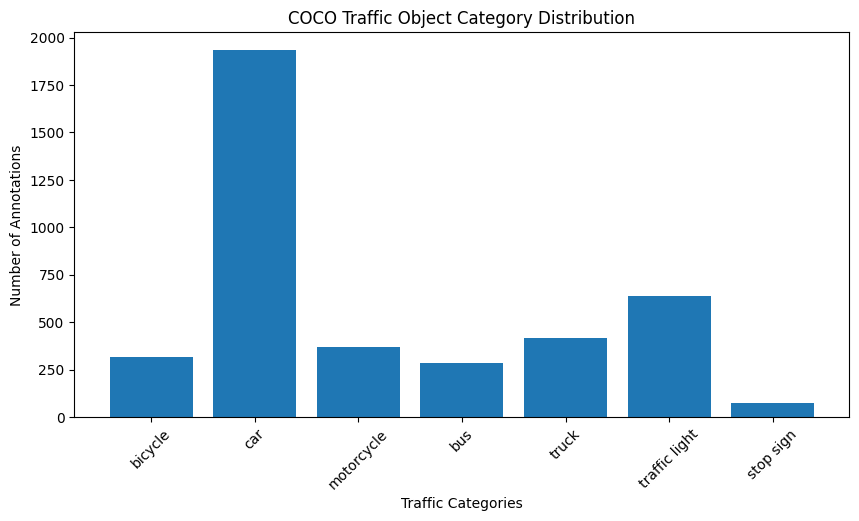

In [8]:
plt.figure(figsize=(10, 5))

plt.bar(
    df["Traffic Category"],
    df["Annotation Count"]
)

plt.title("COCO Traffic Object Category Distribution")
plt.xlabel("Traffic Categories")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=45)

plt.show()

In [9]:
traffic_image_ids = set()

for cat_id in category_ids:
    ann_ids = coco.getAnnIds(catIds=[cat_id])
    annotations = coco.loadAnns(ann_ids)

    for ann in annotations:
        traffic_image_ids.add(ann["image_id"])

print("Total images containing traffic objects:", len(traffic_image_ids))

selected_image_ids = list(traffic_image_ids)[:20]

print("Selected images:", len(selected_image_ids))

Total images containing traffic objects: 952
Selected images: 20


In [10]:
image_folder = "/content/coco_dataset/traffic_images"

os.makedirs(image_folder, exist_ok=True)

image_paths = {}

for image_id in tqdm(selected_image_ids):

    image_info = coco.loadImgs([image_id])[0]

    image_url = image_info["coco_url"]
    image_path = os.path.join(
        image_folder,
        image_info["file_name"]
    )

    if not os.path.exists(image_path):
        response = requests.get(image_url, timeout=30)
        response.raise_for_status()

        with open(image_path, "wb") as f:
            f.write(response.content)

    image_paths[image_id] = image_path

print("Selected traffic images downloaded successfully!")

100%|██████████| 20/20 [00:08<00:00,  2.45it/s]

Selected traffic images downloaded successfully!


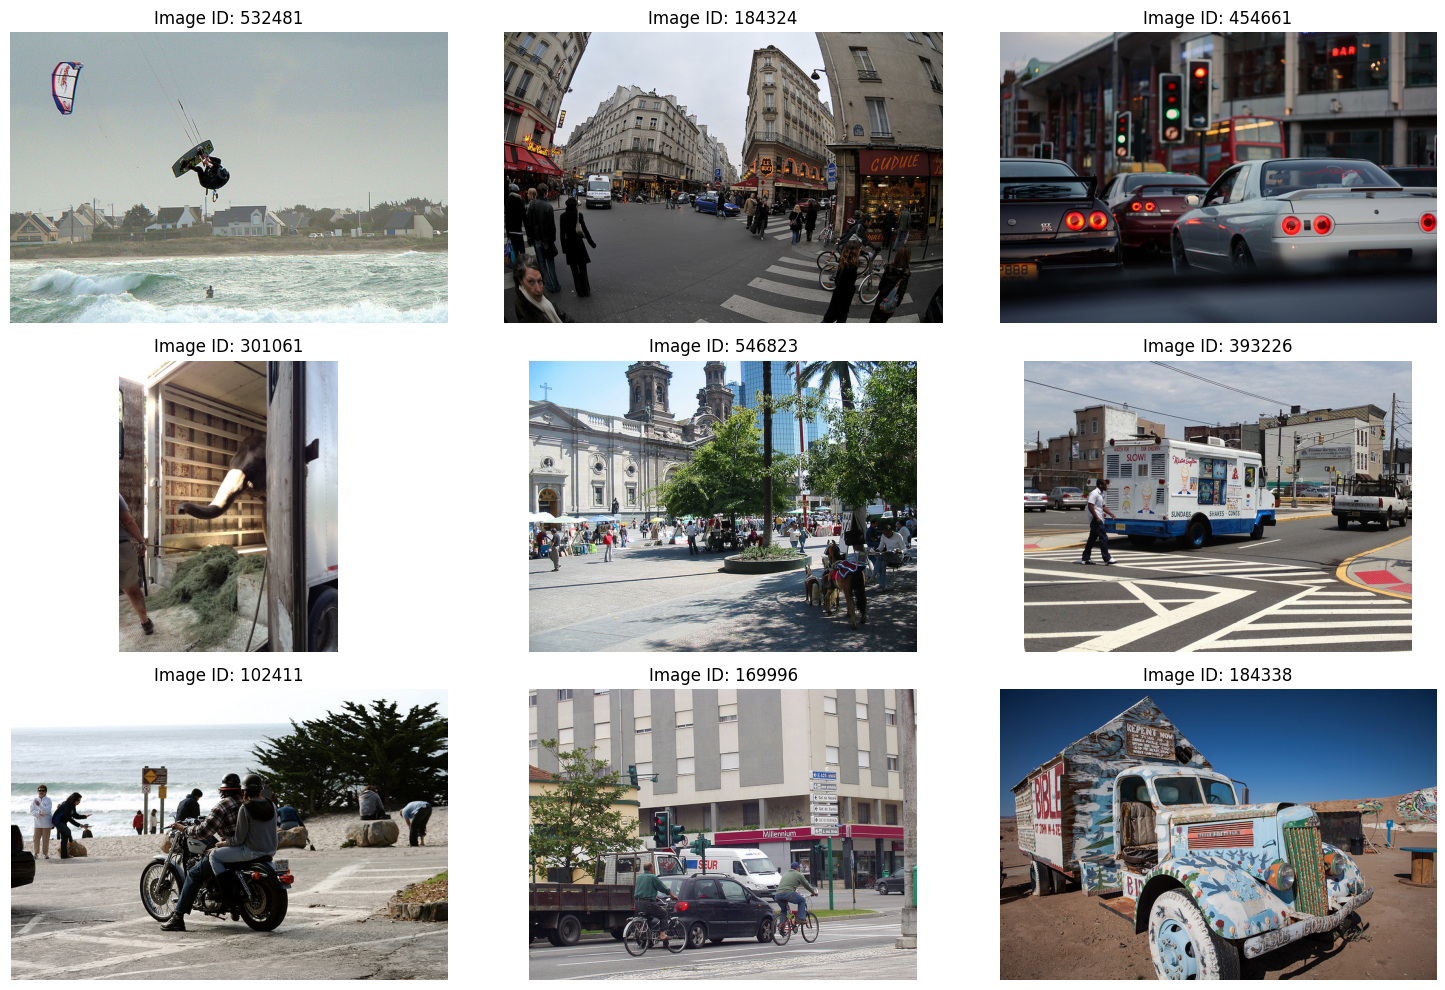

In [11]:
plt.figure(figsize=(15, 10))

for i, image_id in enumerate(selected_image_ids[:9]):

    image_path = image_paths[image_id]

    image = Image.open(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(f"Image ID: {image_id}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
image_id = selected_image_ids[0]

ann_ids = coco.getAnnIds(imgIds=[image_id])
annotations = coco.loadAnns(ann_ids)

print("Image ID:", image_id)
print("Total Objects:", len(annotations))

for ann in annotations[:10]:

    category = coco.loadCats(ann["category_id"])[0]

    print("Object:", category["name"])
    print("Bounding Box:", ann["bbox"])
    print("Area:", ann["area"])
    print("-------------------")

Image ID: 532481
Total Objects: 10
Object: person
Bounding Box: [250.82, 168.26, 70.11, 64.88]
Area: 2188.0864999999994
-------------------
Object: car
Bounding Box: [435.35, 294.23, 13.46, 7.81]
Area: 82.66089999999997
-------------------
Object: car
Bounding Box: [447.44, 293.91, 12.16, 7.65]
Area: 72.87609999999988
-------------------
Object: car
Bounding Box: [460.59, 291.71, 12.75, 8.45]
Area: 95.9415
-------------------
Object: car
Bounding Box: [407.07, 287.25, 12.65, 9.86]
Area: 102.19785000000046
-------------------
Object: car
Bounding Box: [618.06, 289.31, 11.6, 7.95]
Area: 74.7255500000002
-------------------
Object: car
Bounding Box: [512.3, 294.07, 21.18, 5.57]
Area: 91.82754999999982
-------------------
Object: person
Bounding Box: [285.55, 370.56, 12.07, 19.21]
Area: 153.10854999999992
-------------------
Object: kite
Bounding Box: [61.61, 43.76, 46.28, 78.29]
Area: 2501.90015
-------------------
Object: surfboard
Bounding Box: [238.54, 158.48, 61.16, 55.39]
Area: 975.4

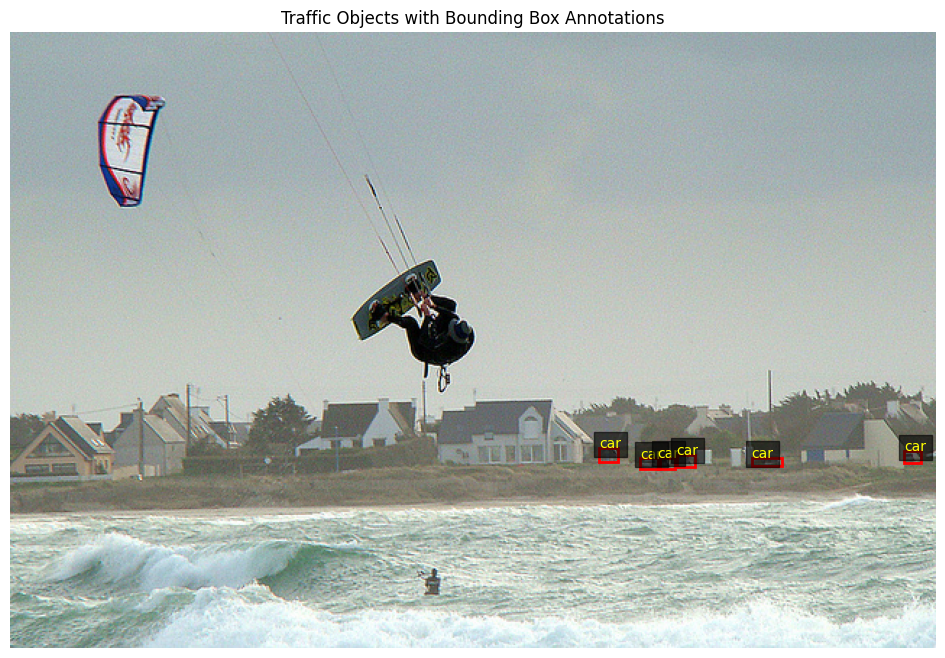

In [13]:
image_id = selected_image_ids[0]

image_path = image_paths[image_id]

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

ann_ids = coco.getAnnIds(imgIds=[image_id])
annotations = coco.loadAnns(ann_ids)

plt.figure(figsize=(12, 8))

plt.imshow(image)

ax = plt.gca()

for ann in annotations:

    if ann["category_id"] not in category_ids:
        continue

    x, y, w, h = ann["bbox"]

    category = coco.loadCats(ann["category_id"])[0]

    rectangle = plt.Rectangle(
        (x, y),
        w,
        h,
        fill=False,
        edgecolor="red",
        linewidth=2
    )

    ax.add_patch(rectangle)

    plt.text(
        x,
        y,
        category["name"],
        color="yellow",
        fontsize=10,
        bbox=dict(facecolor="black", alpha=0.6)
    )

plt.title("Traffic Objects with Bounding Box Annotations")
plt.axis("off")
plt.show()

In [14]:
annotation_data = []

for image_id in selected_image_ids:

    ann_ids = coco.getAnnIds(imgIds=[image_id])
    annotations = coco.loadAnns(ann_ids)

    for ann in annotations:

        if ann["category_id"] not in category_ids:
            continue

        category = coco.loadCats(ann["category_id"])[0]

        annotation_data.append({
            "Image ID": image_id,
            "Category": category["name"],
            "X": ann["bbox"][0],
            "Y": ann["bbox"][1],
            "Width": ann["bbox"][2],
            "Height": ann["bbox"][3],
            "Area": ann["area"]
        })

annotation_df = pd.DataFrame(annotation_data)

display(annotation_df.head(20))

print("Total traffic annotations:", len(annotation_df))

,Image ID,Category,X,Y,Width,Height,Area
0,532481,car,435.35,294.23,13.46,7.81,82.66090
1,532481,car,447.44,293.91,12.16,7.65,72.87610
2,532481,car,460.59,291.71,12.75,8.45,95.94150
3,532481,car,407.07,287.25,12.65,9.86,102.19785
4,532481,car,618.06,289.31,11.60,7.95,74.72555
5,532481,car,512.30,294.07,21.18,5.57,91.82755
6,184324,bicycle,460.65,338.17,87.74,55.75,1818.06390
7,184324,bicycle,455.17,303.56,78.01,55.34,1322.73730
8,184324,car,276.71,237.19,68.16,33.19,1243.23445
9,184324,car,243.62,234.27,27.64,16.15,242.02350


Total traffic annotations: 88


Traffic Object Analysis:
Category
car              35
traffic light    19
bicycle          13
truck            10
motorcycle        8
bus               2
stop sign         1
Name: count, dtype: int64


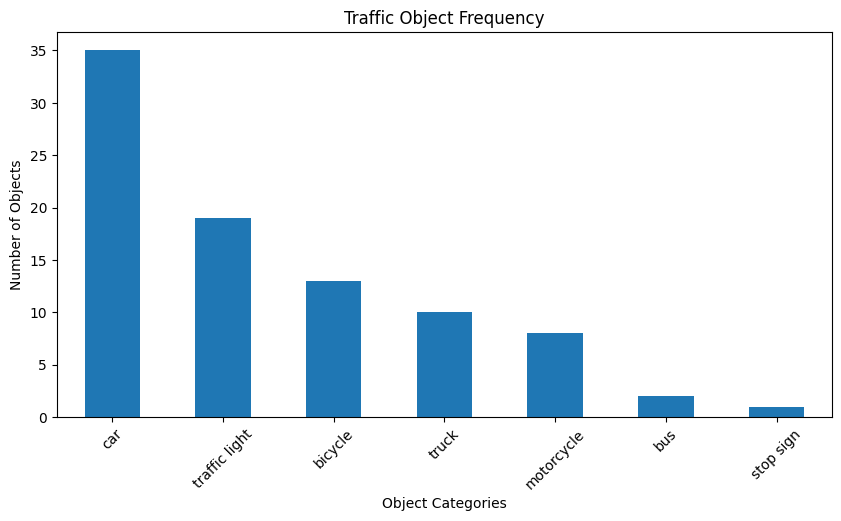

In [15]:
object_counts = annotation_df["Category"].value_counts()

print("Traffic Object Analysis:")
print(object_counts)

object_counts.plot(
    kind="bar",
    figsize=(10, 5),
    title="Traffic Object Frequency"
)

plt.xlabel("Object Categories")
plt.ylabel("Number of Objects")
plt.xticks(rotation=45)
plt.show()

In [16]:
csv_path = "/content/coco_dataset/traffic_annotations.csv"

annotation_df.to_csv(csv_path, index=False)

print("CSV file saved successfully!")
print(csv_path)

CSV file saved successfully!
/content/coco_dataset/traffic_annotations.csv


In [17]:
print("========== COCO DATASET EXPLORATION ==========")

print("Dataset: COCO 2017 Validation Dataset")

print("Total COCO Images:", len(coco.imgs))

print("Total COCO Categories:", len(coco.cats))

print("Traffic Categories:", len(traffic_categories))

print("Selected Traffic Images:", len(selected_image_ids))

print("Total Traffic Annotations:", len(annotation_df))

print("\nTraffic Categories Explored:")

for category in traffic_categories:
    print("-", category)

print("\nBounding Box Format: [x, y, width, height]")

print("\n========== EXPLORATION COMPLETED ==========")

========== COCO DATASET EXPLORATION ==========
Dataset: COCO 2017 Validation Dataset
Total COCO Images: 5000
Total COCO Categories: 80
Traffic Categories: 7
Selected Traffic Images: 20
Total Traffic Annotations: 88

Traffic Categories Explored:
- bicycle
- car
- motorcycle
- bus
- truck
- traffic light
- stop sign

Bounding Box Format: [x, y, width, height]

========== EXPLORATION COMPLETED ==========
